# 01 - Exploratory data analysis

**Goal:** understand the network flow data before modeling, and turn each finding into a decision
for `src/features.py` and `src/train.py`. Each section asks a **question**, shows what I found, and ends
with the **decision** it led to. `notebooks/02_model_development.ipynb` then builds and checks the model.

Checks: shape and types, missing values, class balance, duplicates (and duplicates with conflicting labels),
constant columns, cardinality, heavy tails, saturated counters, label leakage (IPs, ports, timestamps),
and how the data changes over time.

Plots are saved to `reports/figures/`. The summary at the end lists every finding and the decision it led to.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Repo root, whether the notebook runs from notebooks/ or from the repo root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # so the notebook reuses the project code instead of copying it
from src import config
from src.features import load_raw, port_service, repair_timestamp

FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.3f}".format)

# Large fonts and thick lines so every plot is easy to read.
plt.rcParams.update({
    "figure.figsize": (12, 7),
    "figure.facecolor": "white",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,
    "lines.linewidth": 3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d9d9d9",
    "axes.axisbelow": True,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

# Okabe-Ito colorblind-safe colors: one fixed color per label, used in every plot.
LABEL_COLORS = {"benign": "#0072B2", "malicious": "#D55E00", "outlier": "#009E73"}
LABELS = list(LABEL_COLORS)
INK = "#1a1a1a"

## 1. Load the data

**Question:** What exactly is in the file?

In [2]:
# Same loader as training (src/features.py): DATA_PATH if set, otherwise the single CSV in data/raw/.
df = load_raw()
print(f"Rows:    {len(df):,}")
print(f"Columns: {df.shape[1]}")
df.head(3)

Rows:    1,965,386
Columns: 16


,avg_ipt,bytes_in,bytes_out,dest_ip,dest_port,entropy,num_pkts_out,num_pkts_in,proto,src_ip,src_port,time_end,time_start,total_entropy,label,duration
0,229.583,1359,745,786,22,6.929,14,14,6,63760,39032,1593951420997637,159395141801898,"14,579.327",malicious,2.979
1,235.000,0,23,786,2250,3.969,5,3,6,4837,51307,1593951421585135,1593951421116074,91.287,malicious,0.469
2,0.000,56,56,786,0,1.020,1,1,1,14618,0,1593951418925389,1593951418925299,114.267,malicious,0.000


**What I found:** the columns match the **LUFlow** dataset (Lancaster University): real traffic captured around a monitored
network, with labels made by matching each flow's IP IDs (either end) against cyber threat intelligence about
known malicious hosts.
`src_ip` / `dest_ip` are integers that look like **network numbers (autonomous systems)** rather than single machines:
786 is JANET, the UK academic network Lancaster belongs to, and 15169 is Google. `time_start` / `time_end` are
epoch microseconds.

**Decision:** treat the IP columns as network IDs, and check them for label leakage before using them (section 8).

## 2. Types, missing values, unique values

**Question:** Is anything missing, constant, or stored as the wrong type?

In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
print(f"Missing values in total: {df.isna().sum().sum()}")
print(f"Constant columns:        {constant_cols or 'none'}")
overview

Missing values in total: 0
Constant columns:        none


,dtype,missing,unique,min,max
avg_ipt,float64,0,38009,0.000,"4,294,967,300.000"
bytes_in,int64,0,15083,0.000,"65,498.000"
bytes_out,int64,0,31477,0.000,"65,534.000"
dest_ip,int64,0,319,4.000,"396,507.000"
dest_port,int64,0,20409,0.000,"65,534.000"
duration,float64,0,268859,0.000,43.004
entropy,float64,0,993822,0.000,135.108
label,str,0,3,NaN,NaN
num_pkts_in,int64,0,256,0.000,255.000
num_pkts_out,int64,0,256,0.000,255.000


**What I found:** no missing values and no constant columns. All features are numeric; only `label` is text. (IDs and timestamps print as decimals here only because of the display format; the very short `time_*` minimums are the ~10% of timestamps that lost trailing zeros, repaired in section 10.)

**Decision:** No imputation or cleaning of missing values is needed.

## 3. Class balance

**Question:** How many flows of each label, and what does that mean for the metric?

In [4]:
counts = df["label"].value_counts().reindex(LABELS)
balance = pd.DataFrame({"rows": counts, "share_%": 100 * counts / len(df)})
balance

,rows,share_%
label,,
benign,1574580,80.116
malicious,315227,16.039
outlier,75579,3.846


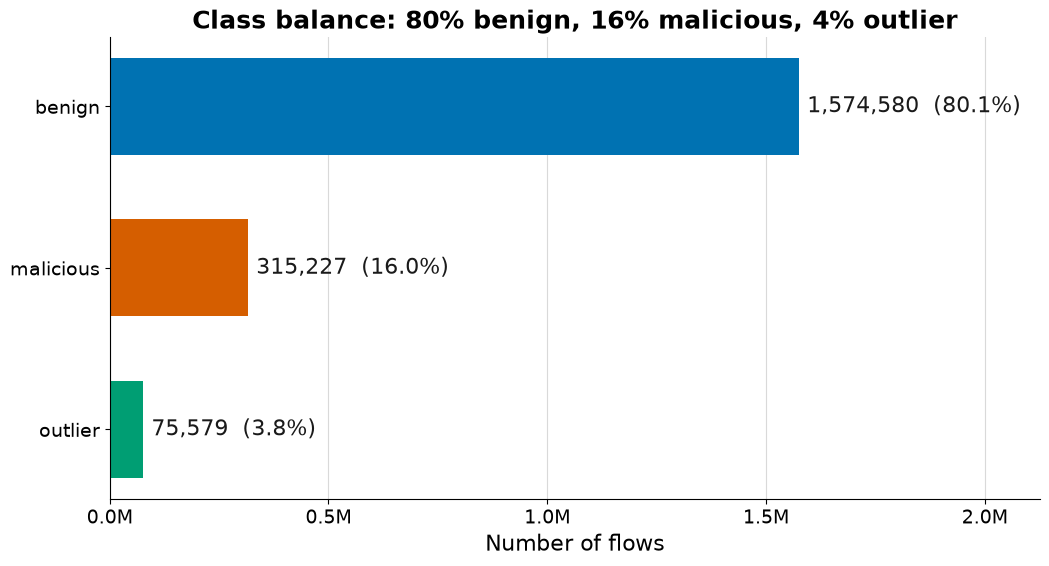

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
positions = np.arange(len(LABELS))
ax.barh(positions, counts.values, height=0.6, color=[LABEL_COLORS[l] for l in LABELS])
ax.set_yticks(positions, LABELS)
ax.invert_yaxis()
for i, (n, share) in enumerate(zip(counts.values, balance["share_%"])):
    ax.text(n + len(df) * 0.01, i, f"{n:,}  ({share:.1f}%)", va="center", color=INK, fontsize=16)
ax.set_xlim(0, counts.max() * 1.35)
ax.xaxis.set_major_locator(plt.MultipleLocator(500_000))
ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1e6:.1f}M")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of flows")
ax.set_title("Class balance: 80% benign, 16% malicious, 4% outlier")
fig.savefig(FIG_DIR / "01_class_balance.png")
plt.show()

**What I found:** there are **three** labels, not two. The brief asks for "outlier or not", so the target definition is a decision
(see the summary at the end). Either way the positive class is a minority, so accuracy is a poor metric:
a model that always says "benign" is already 80% accurate.

**Decision:** Choose the target on purpose (`docs/decisions.md`, decision 4), and never judge a model by accuracy.

## 4. Duplicates and conflicting labels

**Question:** Are there copies, and do identical flows ever get different labels?

In [6]:
# Who/when columns; everything else describes how the traffic behaved.
META_COLS = config.DROP_COLS  # the columns the model never sees
BEHAVIOUR_COLS = [c for c in df.columns if c not in META_COLS + ["label"]]

labels_per_group = df.groupby(BEHAVIOUR_COLS, sort=False)["label"].transform("nunique")
duplicates = pd.Series({
    "exact duplicate rows (all 16 columns)": df.duplicated().sum(),
    "duplicate rows on behaviour columns only": df.duplicated(subset=BEHAVIOUR_COLS).sum(),
    "rows whose behaviour twin has a different label": (labels_per_group > 1).sum(),
}, name="rows").to_frame()
duplicates["share_%"] = 100 * duplicates["rows"] / len(df)
print("Behaviour columns:", BEHAVIOUR_COLS)
duplicates

Behaviour columns: ['avg_ipt', 'bytes_in', 'bytes_out', 'dest_port', 'entropy', 'num_pkts_out', 'num_pkts_in', 'proto', 'total_entropy', 'duration']


,rows,share_%
exact duplicate rows (all 16 columns),1039,0.053
duplicate rows on behaviour columns only,498314,25.355
rows whose behaviour twin has a different label,167530,8.524


In [7]:
# Which labels disagree? One row per group of identical-behaviour flows.
conflicts = (
    df.loc[labels_per_group > 1]
    .groupby(BEHAVIOUR_COLS, sort=False)["label"]
    .agg(lambda s: " + ".join(sorted(s.unique())))
    .value_counts()
    .rename("groups")
    .to_frame()
)
conflicts

,groups
label,
malicious + outlier,8728
benign + malicious,34
benign + malicious + outlier,2
benign + outlier,1


**What I found:**

- Exact duplicates (all 16 columns, including IPs and microsecond timestamps) are logging copies: drop them.
- A quarter of rows repeat the same behaviour from different IPs or times (scanners, repeated internal traffic).
  That is real traffic, and how often a pattern occurs matters, so these rows are **kept** (see the next cell for
  why removing them goes wrong).
- Almost every conflict is **malicious vs outlier**: the same traffic gets a different label depending on who sent it.
  So "outlier vs malicious" is hard to learn from behaviour alone.

In [8]:
# The model treats every ephemeral port (49152+) as one value. Seen that way, one very common pattern is shared:
# a single empty TCP packet to an ephemeral port.
empty_packet = (df["num_pkts_out"].eq(1) & df["num_pkts_in"].eq(0) & df["bytes_out"].eq(0) & df["bytes_in"].eq(0)
                & df["proto"].eq(6) & df["duration"].eq(0) & port_service(df[["dest_port"]]).ravel().__eq__("ephemeral"))
pattern = df.loc[empty_packet].assign(bad=lambda d: d["label"].ne("benign"))
pd.DataFrame({
    "flows": pattern.groupby("bad").size(),
    "distinct dest ports": pattern.groupby("bad")["dest_port"].nunique(),
}).rename(index={False: "benign", True: "malicious or outlier"})

,flows,distinct dest ports
bad,,
benign,125815,49
malicious or outlier,6529,4203


In real traffic this pattern is **95% benign** (internal traffic on a few ports). But benign uses only
49 ports while scanners spread over 4,203. De-duplicating on the raw port would keep 49 benign rows against
~4,200 bad ones, and the model would learn "this pattern is 99% bad". An earlier version did exactly that and
flagged 126,136 benign flows on this day. **So only exact copies are dropped** (`docs/decisions.md`, decision 2).

**Decision:** Drop exact copies only; keep repeated flows.

## 5. Categorical columns and cardinality

**Question:** Which columns are codes rather than quantities, and how many values do they have?

In [9]:
PROTO_NAMES = {1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE", 58: "ICMPv6"}
proto_table = pd.crosstab(df["proto"].map(PROTO_NAMES), df["label"]).reindex(columns=LABELS)
proto_table["total"] = proto_table.sum(axis=1)
proto_table.sort_values("total", ascending=False)

label,benign,malicious,outlier,total
proto,,,,
TCP,1567652,207223,49271,1824146
UDP,6903,86877,24995,118775
ICMP,0,21125,1313,22438
ICMPv6,24,0,0,24
GRE,0,2,0,2
IGMP,1,0,0,1


In [10]:
cardinality = df[["proto", "dest_port", "src_port", "src_ip", "dest_ip"]].nunique().rename("unique values").to_frame()
cardinality

,unique values
proto,6
dest_port,20409
src_port,60971
src_ip,802
dest_ip,319


**What I found:**

- `proto` is a code, not a quantity (17 is not "more" than 6), so treat it as **categorical**. ICMP is never benign.
- Ports have tens of thousands of values: too many to one-hot encode directly. Group them (for example
  well-known / registered / ephemeral, plus the most common ports) in feature engineering.

**Decision:** One-hot encode `proto`; group `dest_port` before one-hot encoding it.

## 6. Heavy-tailed numeric columns

**Question:** What do the numeric columns look like?

In [11]:
NUMERIC_COLS = config.NUMERIC_COLS
tails = pd.DataFrame({
    "median": df[NUMERIC_COLS].median(),
    "p99": df[NUMERIC_COLS].quantile(0.99),
    "max": df[NUMERIC_COLS].max(),
    "% zeros": 100 * (df[NUMERIC_COLS] == 0).mean(),
    "skew": df[NUMERIC_COLS].skew(),
})
tails

,median,p99,max,% zeros,skew
avg_ipt,0.000,"1,801.415","4,294,967,300.000",83.266,39.963
bytes_in,0.000,"11,584.000","65,498.000",77.201,9.576
bytes_out,"1,004.000","22,871.150","65,534.000",29.889,2.490
entropy,2.514,7.288,135.108,23.920,1.734
num_pkts_out,3.000,42.000,255.000,0.002,12.442
num_pkts_in,0.000,22.000,255.000,56.865,14.415
total_entropy,"11,489.990","56,643.220","3,496,618.000",23.920,38.893
duration,0.000,29.025,43.004,21.221,7.028


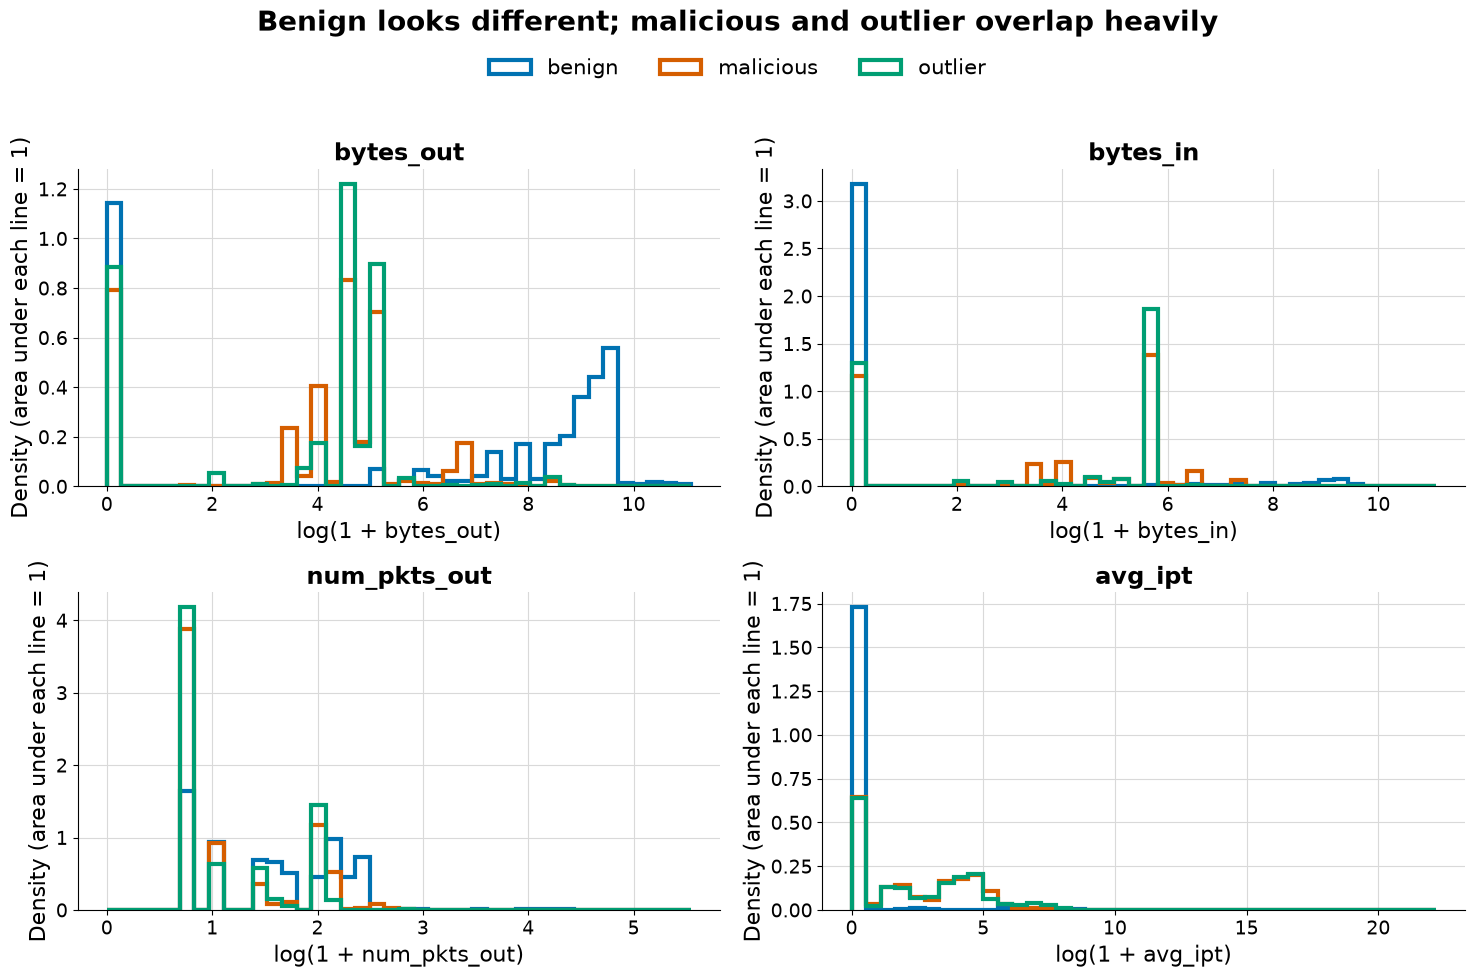

In [12]:
PLOT_COLS = ["bytes_out", "bytes_in", "num_pkts_out", "avg_ipt"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flat, PLOT_COLS):
    values = np.log1p(df[col])
    bins = np.linspace(0, values.max(), 41)
    for label in LABELS:
        ax.hist(values[df["label"] == label], bins=bins, density=True, histtype="step",
                linewidth=3, color=LABEL_COLORS[label], label=label)
    ax.set_title(col, fontsize=17)
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_ylabel("Density (area under each line = 1)")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Benign looks different; malicious and outlier overlap heavily", fontsize=20, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG_DIR / "02_numeric_by_label.png")
plt.show()

**What I found:** the medians are tiny and the maximums are huge: `avg_ipt` has a 99th percentile of about 1,800 but a maximum of
4.3 billion (skew about 40), and 83% of its values are exactly zero.
A linear model would be dominated by a few giant values, so apply **`log1p`** (log of 1 + x keeps zeros at zero)
and then scale.

In the plot, benign has its own shape: many benign flows send 1 KB or more out (61% of benign vs 6% of malicious
and 2% of outlier), almost nothing comes back in, and `avg_ipt` is near zero. Every class also has many flows with
0 bytes out (benign 32%, malicious 22%, outlier 25%), so that spike does not separate them. The malicious and outlier lines overlap heavily, which matches
the duplicate check above.

**Decision:** `log1p`, then `StandardScaler`, for every numeric column.

## 7. Saturated counters

**Question:** Do any counters hit a hard limit?

In [13]:
saturation = pd.Series({
    "avg_ipt at about 2^32 (overflow)": (df["avg_ipt"] > 4.29e9).sum(),
    "num_pkts_out = 255 (8-bit cap)": (df["num_pkts_out"] == 255).sum(),
    "num_pkts_in = 255 (8-bit cap)": (df["num_pkts_in"] == 255).sum(),
    "bytes_out >= 65,534 (16-bit cap)": (df["bytes_out"] >= 65_534).sum(),
    "bytes_in >= 65,534 (16-bit cap)": (df["bytes_in"] >= 65_534).sum(),
}, name="rows").to_frame()
saturation

,rows
avg_ipt at about 2^32 (overflow),16
num_pkts_out = 255 (8-bit cap),21
num_pkts_in = 255 (8-bit cap),9
"bytes_out >= 65,534 (16-bit cap)",1
"bytes_in >= 65,534 (16-bit cap)",0


**What I found:** packet and byte counters stop at 255 and about 65,535: the capture tool stores them in 8- and 16-bit fields,
so very large flows are cut off. Only a few dozen rows hit the cap, so no action now; worth knowing in production.

**Decision:** No change now; watch for capped values in production.

## 8. Leakage check: IP addresses

**Question:** Can the IP columns give the answer away?

In [14]:
# The monitored network (AS786) appears as source or destination in almost every flow.
HOME_NET = int(df["dest_ip"].mode()[0])


def label_purity(col: str) -> float:
    """Share of rows we would label correctly by guessing the most common label for each value of `col`."""
    table = pd.crosstab(df[col], df["label"])
    return table.max(axis=1).sum() / len(df)


purity = pd.Series({
    "always guess 'benign' (baseline)": counts.max() / len(df),
    "guess from src_ip": label_purity("src_ip"),
    "guess from dest_ip": label_purity("dest_ip"),
}, name="accuracy").to_frame()
benign = df["label"].eq("benign")
internal = df["src_ip"].eq(HOME_NET) & df["dest_ip"].eq(HOME_NET)
print(f"Monitored network ID: {HOME_NET}")
print(f"The network is the destination in {100 * (df['dest_ip'] == HOME_NET).mean():.1f}% of flows "
      f"and the source in {100 * (df['src_ip'] == HOME_NET).mean():.1f}%")
print(f"Benign flows with both ends inside the network: {100 * internal[benign].mean():.1f}%")
print(f"Bad flows sent FROM inside the network (labels match either end): {100 * df['src_ip'].eq(HOME_NET)[~benign].mean():.1f}%")
purity

Monitored network ID: 786
The network is the destination in 97.4% of flows and the source in 82.0%
Benign flows with both ends inside the network: 99.0%
Bad flows sent FROM inside the network (labels match either end): 9.4%


,accuracy
always guess 'benign' (baseline),0.801
guess from src_ip,0.981
guess from dest_ip,0.819


In [15]:
from_home = df["src_ip"] == HOME_NET
source_names = {
    True: f"Monitored network (AS{HOME_NET})\n{from_home.sum():,} flows",
    False: f"All other sources ({df.loc[~from_home, 'src_ip'].nunique()} networks)\n{(~from_home).sum():,} flows",
}
source_mix = 100 * pd.crosstab(from_home.map(source_names), df["label"], normalize="index").reindex(
    index=[source_names[True], source_names[False]], columns=LABELS)
source_mix

label,benign,malicious,outlier
src_ip,,,
"Monitored network (AS786)\n1,611,448 flows",97.712,1.876,0.412
"All other sources (801 networks)\n353,938 flows",0.000,80.520,19.480


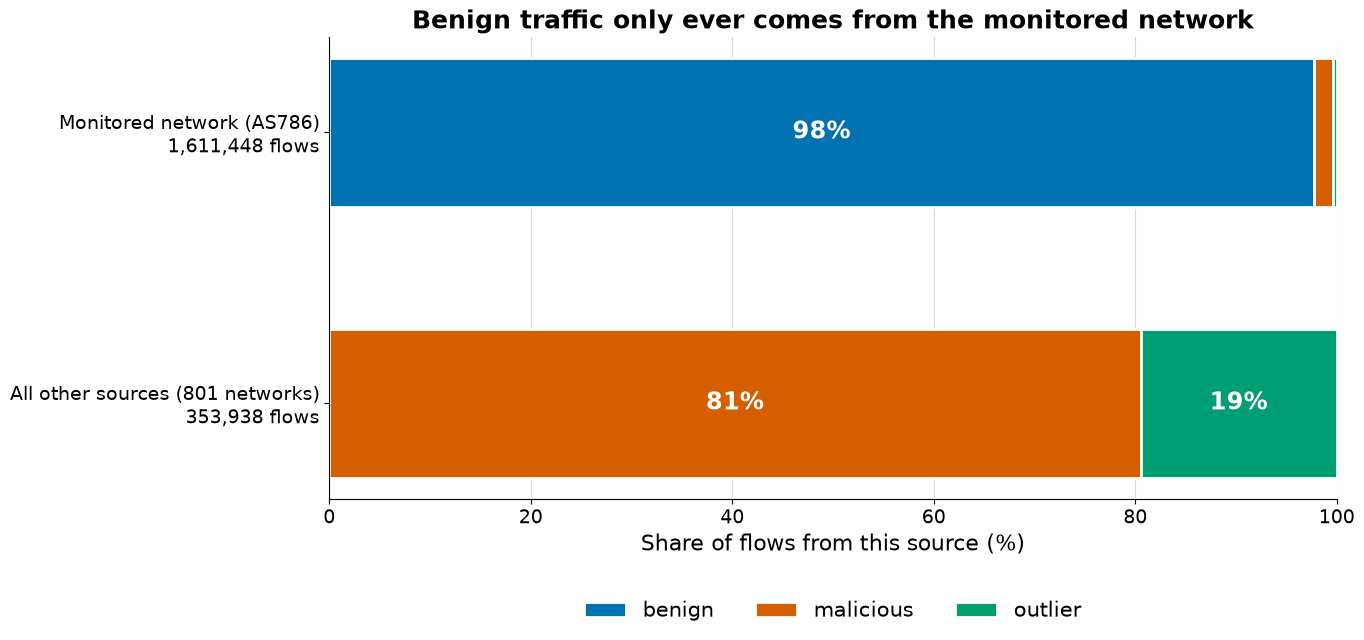

In [16]:
fig, ax = plt.subplots(figsize=(13, 6))
left = np.zeros(len(source_mix))
positions = np.arange(len(source_mix))
for label in LABELS:
    widths = source_mix[label].to_numpy()
    ax.barh(positions, widths, left=left, height=0.55, color=LABEL_COLORS[label],
            edgecolor="white", linewidth=2, label=label)
    for i, (start, width) in enumerate(zip(left, widths)):
        if width >= 6:
            ax.text(start + width / 2, i, f"{width:.0f}%", ha="center", va="center",
                    color="white", fontsize=17, fontweight="bold")
    left += widths
ax.set_yticks(positions, source_mix.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of flows from this source (%)")
ax.set_title("Benign traffic only ever comes from the monitored network")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
fig.savefig(FIG_DIR / "03_label_by_source.png")
plt.show()

**What I found:** this is **the biggest leakage risk**. Labels were made by looking up the IPs in threat-intelligence lists,
so `src_ip` predicts the label 98% of the time and every benign flow comes from one IP. A model given IPs would
memorize addresses instead of learning traffic behaviour, and it would fail on any new attacker IP.

Two limits to say out loud: **99% of benign flows have both ends inside the monitored network**, so the model mostly
learns "this network's internal traffic vs. internet traffic" and will not transfer to another network as is. And
labels match *either* end of a connection, so about 9% of bad flows are sent from inside the network (for example
replies to scanners).

**Decision:** drop `src_ip` and `dest_ip`, and say clearly that results are specific to this network.

## 9. Leakage check: ports

**Question:** What do the ports tell us, and is any of it leakage?

In [17]:
PORT_NAMES = {9200: "Elasticsearch", 445: "SMB (Windows file sharing)", 1900: "SSDP / UPnP",
              0: "no port (ICMP)", 5900: "VNC remote desktop", 5060: "SIP (VoIP)", 22: "SSH",
              3389: "RDP remote desktop", 23: "Telnet", 123: "NTP (time)", 80: "HTTP (web)"}
top_ports = pd.crosstab(df["dest_port"], df["label"]).reindex(columns=LABELS)
top_ports["total"] = top_ports.sum(axis=1)
top_ports = top_ports.sort_values("total", ascending=False).head(10)
top_ports.insert(0, "service", top_ports.index.map(PORT_NAMES).fillna("ephemeral / other"))
top_ports

label,service,benign,malicious,outlier,total
dest_port,,,,,
9200,Elasticsearch,1047129,52,0,1047181
445,SMB (Windows file sharing),0,124766,35167,159933
1900,SSDP / UPnP,0,67273,24729,92002
50854,ephemeral / other,51090,6,0,51096
50850,ephemeral / other,50633,1,0,50634
50846,ephemeral / other,50314,2,2,50318
50734,ephemeral / other,49775,0,0,49775
50858,ephemeral / other,49666,1,0,49667
50862,ephemeral / other,49489,0,0,49489


In [18]:
# The ports that attacks go to: sorted by bad flows (malicious + outlier).
attack_ports = pd.crosstab(df["dest_port"], df["label"]).reindex(columns=LABELS)
attack_ports["bad"] = attack_ports["malicious"] + attack_ports["outlier"]
attack_ports = attack_ports.sort_values("bad", ascending=False).head(10)
attack_ports.insert(0, "service", attack_ports.index.map(PORT_NAMES).fillna("other"))
attack_ports

label,service,benign,malicious,outlier,bad
dest_port,,,,,
445,SMB (Windows file sharing),0,124766,35167,159933
1900,SSDP / UPnP,0,67273,24729,92002
0,no port (ICMP),25,21127,1313,22440
5900,VNC remote desktop,0,20657,1,20658
5060,SIP (VoIP),0,16249,0,16249
22,SSH,0,14941,56,14997
23,Telnet,0,3269,208,3477
123,NTP (time),0,2734,240,2974
80,HTTP (web),55,1099,95,1194


**What I found:**

- Over half of all flows (and two thirds of benign) go to **port 9200 (Elasticsearch)**: internal logging
  traffic. A model will learn "port 9200 means benign". That is real behaviour on this network but would not
  carry over to another network.
- Attacks target classic services: SMB (445), SSDP (1900), VNC, SIP, SSH, RDP (next table). These are legitimate
  signals.
- `src_port` is mostly a random ephemeral number chosen by the sender: noise, not behaviour. Drop it.

**Decision:** Keep `dest_port` (grouped); drop `src_port`.

## 10. Timestamps: corruption, repair, and change over time

**Question:** Can the timestamps be trusted, and does the traffic change during the day?

In [19]:
digit_counts = df["time_start"].astype(str).str.len().value_counts().sort_index()
print("time_start digit lengths (16 is correct for epoch microseconds):")
print(digit_counts.to_string())
print(f"Short (corrupt) timestamps: {(digit_counts.drop(16).sum() / len(df)):.1%} of rows")

time_start digit lengths (16 is correct for epoch microseconds):
time_start
11         24
12        163
13       1819
14      17925
15     176720
16    1768735
Short (corrupt) timestamps: 10.0% of rows


In [20]:
# Is the corruption related to the label? (If it were, a "timestamp length" would leak the label.)
corrupt = df["time_start"].astype(str).str.len().ne(16)
100 * pd.crosstab(corrupt.rename("timestamp corrupt"), df["label"], normalize="index").reindex(columns=LABELS)

label,benign,malicious,outlier
timestamp corrupt,,,
False,80.117,16.039,3.844
True,80.101,16.036,3.863


In [21]:
# repair_timestamp (src/features.py): the fraction lost its trailing zeros (018980 became 01898); pad back to 6 digits.
start_us = repair_timestamp(df["time_start"])
end_us = repair_timestamp(df["time_end"])
error_s = ((end_us - start_us) / 1e6 - df["duration"]).abs()
print(f"Max |(end - start) - duration| after repair: {error_s.max():.6f} s")
start = pd.to_datetime(start_us, unit="us")
print(f"Time range: {start.min()}  to  {pd.to_datetime(end_us, unit='us').max()}  (UTC)")

Max |(end - start) - duration| after repair: 0.000003 s
Time range: 2020-07-04 23:59:19.510707  to  2020-07-05 23:59:41.238016  (UTC)


In [22]:
hourly = pd.crosstab(start.dt.floor("h"), df["label"]).reindex(columns=LABELS)
hourly["total"] = hourly.sum(axis=1)
burst = hourly.loc["2020-07-05 16:00":"2020-07-05 17:00", "total"].sum() / len(df)
print(f"Share of all rows between 16:00 and 18:00: {burst:.1%}")
hourly

Share of all rows between 16:00 and 18:00: 62.9%


label,benign,malicious,outlier,total
time_start,,,,
2020-07-04 23:00:00,32,16,1,49
2020-07-05 00:00:00,3140,2873,414,6427
2020-07-05 01:00:00,3847,5411,385,9643
2020-07-05 02:00:00,2746,6772,283,9801
2020-07-05 03:00:00,200918,31845,9716,242479
2020-07-05 04:00:00,87220,38538,4871,130629
2020-07-05 05:00:00,4350,3192,374,7916
2020-07-05 06:00:00,3685,52718,1633,58036
2020-07-05 07:00:00,3560,10552,4611,18723


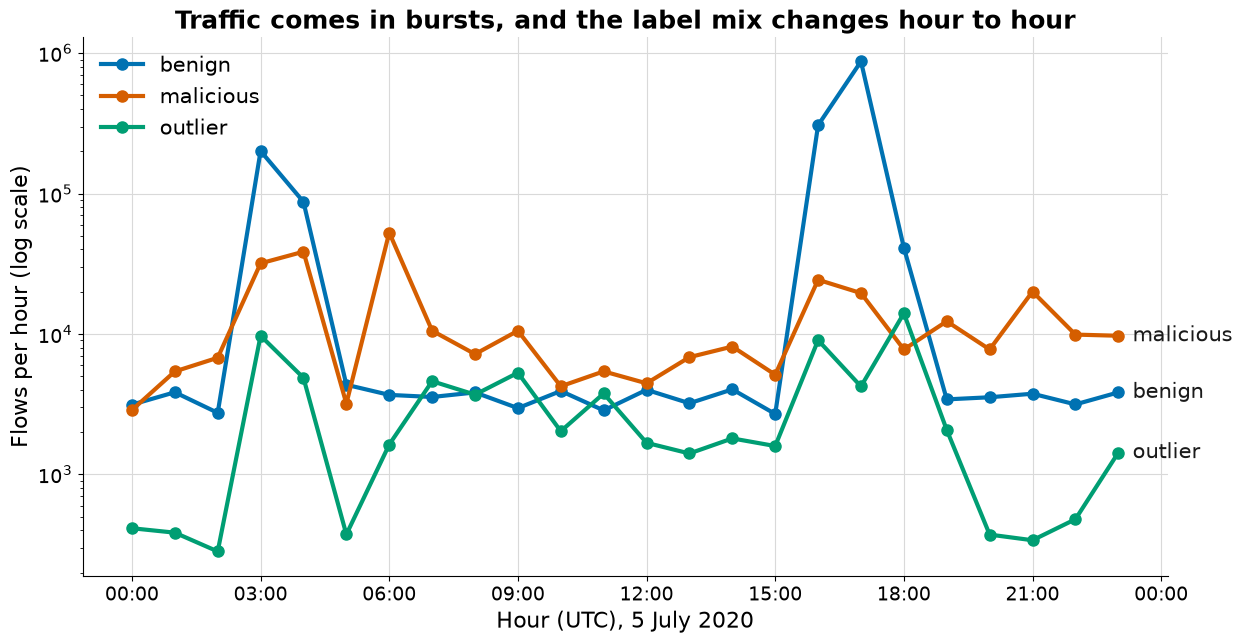

In [23]:
# The capture starts 41 seconds before midnight; skip that partial hour so it does not distort the plot.
day = hourly.loc[hourly.index >= "2020-07-05"]
fig, ax = plt.subplots(figsize=(14, 7))
for label in LABELS:
    series = day[label].clip(lower=1)  # log scale cannot show 0
    ax.plot(day.index, series, marker="o", markersize=8, color=LABEL_COLORS[label], label=label)
    ax.text(day.index[-1] + pd.Timedelta(minutes=20), series.iloc[-1], label,
            color=INK, fontsize=15, va="center")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=3))
ax.set_xlabel("Hour (UTC), 5 July 2020")
ax.set_ylabel("Flows per hour (log scale)")
ax.set_title("Traffic comes in bursts, and the label mix changes hour to hour")
ax.legend(loc="upper left", frameon=False)
fig.savefig(FIG_DIR / "04_label_mix_over_time.png")
plt.show()

In [24]:
# What a time-based split would look like: train on the first 80% of the day, test on the last 20%.
order = start.sort_values().index
cut = int(len(df) * 0.8)
time_split = pd.DataFrame({
    "first 80% of time (%)": 100 * df.loc[order[:cut], "label"].value_counts(normalize=True),
    "last 20% of time (%)": 100 * df.loc[order[cut:], "label"].value_counts(normalize=True),
}).reindex(LABELS)
print(f"Cut point: {start.loc[order[cut]]}")
time_split

Cut point: 2020-07-05 17:37:32.041347


,first 80% of time (%),last 20% of time (%)
label,,
benign,81.034,76.443
malicious,15.364,18.740
outlier,3.603,4.817


**What I found:**

- About 10% of timestamps were stored wrongly (trailing zeros dropped). The repair is exact, so this is a
  formatting bug, not missing data. It is equally common in every label, so it does not leak the label.
- The data covers **one day**. Traffic arrives in bursts (16:00 to 18:00 holds 63% of all rows) and the label
  mix moves a lot from hour to hour.
- Over the whole day the mix evens out: a train-on-first-80%, test-on-last-20% split gives 81% vs 76% benign.
  The bigger risk of a random split is that the same burst lands in both train and test, so the score looks
  better than reality. A **time-based split** is the honest extra check.
- Timestamps are not used as model features: the hour of day on a single day would not generalize.

**Decision:** Repair timestamps only to sort flows by time; never use them as inputs; add a time-based check (notebook 02, section 8).

## Summary: what the data says, and what I decided

**The data.** 1,965,386 flows and 16 columns from one day (5 July 2020, UTC), with no missing values and no constant
columns. It is the **LUFlow** dataset (Lancaster University): real traffic around one monitored network, labelled by
matching each flow's IP IDs (either end) against threat intelligence. The "IP" columns are **network numbers
(autonomous systems)**, not single machines: 786 is JANET, the UK academic network; 15169 is Google.

| What I found | Decision |
|---|---|
| Three labels: benign 80.1%, malicious 16.0%, outlier 3.8%; the brief says "outlier or not" | Target "not benign" = 1 (`src/config.py`; `docs/decisions.md`, decision 4); report recall per label |
| The positive class is a minority: "always benign" is already 80% accurate | Never judge a model by accuracy; use recall inside a false-alarm budget |
| `src_ip` alone guesses the label 98.1% of the time; 99.0% of benign flows have both ends inside the monitored network (AS786); 9.4% of bad flows are sent from inside it | Drop `src_ip` and `dest_ip`; say that results are specific to this network |
| Malicious and outlier behave almost the same: 8,728 groups of identical flows carry both labels | One "not benign" target; expect little separation between the two |
| 1,039 exact copies (0.05%); 25% of rows repeat the same behaviour from other IPs or at other times | Drop exact copies only; keep repeats, because how often a pattern occurs matters (decision 2) |
| With every ephemeral port counted as one, an empty one-packet TCP flow is 95% benign (125,815 flows) and 5% bad (6,529) | A known ambiguous pattern; never de-duplicate it away |
| Heavy tails and many zeros: `avg_ipt` is 83% zeros, with a 99th percentile of about 1,800 and a maximum of 4.3 billion; a few dozen counters stop at 255 or about 65,535 | `log1p`, then `StandardScaler`; watch capped values in production |
| `proto` is a code (TCP, UDP, ICMP...), and ICMP is never benign | One-hot encode it |
| `dest_port` has 20,409 values; port 9200 (Elasticsearch) carries 53% of all flows and 66.5% of benign ones; `src_port` is a random reply port | Group `dest_port`; drop `src_port` |
| 10% of timestamps lost trailing zeros (exact repair, same rate in every label); traffic comes in bursts (63% of rows between 16:00 and 18:00) and the label mix changes by hour | Timestamps only sort flows by time, never as inputs; add a time-based check (notebook 02) |

### Decisions

These feed `src/config.py` and `src/features.py`, and each one is a row in `docs/decisions.md`.

1. **Target = not benign:** malicious + outlier = 1, benign = 0.
2. **Drop IPs, source port and timestamps** as inputs: the IPs leak the label, the source port is noise, and the hour of one day does not generalize.
3. **Drop exact duplicates only:** repeated flows are real traffic, and their frequency matters.
4. **Log transform:** `log1p`, then scale, for the heavy-tailed numeric columns.
5. **Group ports:** every ephemeral port is one value, rare ports share one column, plus the port range; `proto` is one-hot.
6. **Evaluate on traffic as it arrives:** at a fixed false-alarm budget, never by accuracy, with a time-based check (notebook 02).